# Análisis exploratorio del corpus

## Objetivo

Analizar el texto extraído de las diapositivas de Inteligencia Artificial
para justificar su preparación y selección como base de un asistente de estudio.

Se estudiarán:
- Cantidad de documentos y páginas.
- Distribución de palabras por diapositiva.
- Páginas con poco texto o sin texto extraído.
- Coincidencias textuales entre páginas.
- Decisiones de inclusión y exclusión.

Los resultados describen el texto extraído, no la totalidad del contenido
visual de los PDF. Una página con poco texto puede contener gráficos,
fórmulas o imágenes relevantes.

In [1]:
import hashlib
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Encuentra la raíz tanto si Jupyter inicia en el proyecto
# como si inicia dentro de notebooks/.
actual = Path.cwd().resolve()

RAIZ = next(
    (
        carpeta
        for carpeta in (actual, *actual.parents)
        if (carpeta / "src" / "preparar_paginas.py").is_file()
    ),
    None,
)

if RAIZ is None:
    raise RuntimeError("No se encontró la raíz del proyecto.")

DATOS = RAIZ / "data" / "processed"


def leer_jsonl(nombre):
    ruta = DATOS / nombre

    if not ruta.is_file():
        raise FileNotFoundError(
            f"Falta {ruta}. Ejecutá primero los programas de preparación."
        )

    with ruta.open(encoding="utf-8") as archivo:
        return [
            json.loads(linea)
            for linea in archivo
            if linea.strip()
        ]


paginas = pd.DataFrame(leer_jsonl("paginas_limpias.jsonl"))
decisiones = pd.DataFrame(leer_jsonl("decisiones_paginas.jsonl"))
corpus = pd.DataFrame(leer_jsonl("corpus_busqueda.jsonl"))

if paginas.empty or decisiones.empty or corpus.empty:
    raise ValueError("Uno de los archivos de entrada está vacío.")

print("Python utilizado:", sys.executable)
print("Raíz del proyecto:", RAIZ)
print("Páginas limpias:", len(paginas))
print("Decisiones registradas:", len(decisiones))
print("Fragmentos incluidos:", len(corpus))

huella = hashlib.sha256(
    (DATOS / "corpus_busqueda.jsonl").read_bytes()
).hexdigest()

print("SHA-256 del corpus:", huella)

Python utilizado: /home/joaquin/Proyectos/asistente-estudio-ia/.venv/bin/python
Raíz del proyecto: /home/joaquin/Proyectos/asistente-estudio-ia
Páginas limpias: 742
Decisiones registradas: 742
Fragmentos incluidos: 697
SHA-256 del corpus: 50eacef90daf99538ee6e78fa5a508a4444aad995bc72c91a60f4c0e573224a0


In [2]:
assert paginas["id_pagina"].is_unique, "Hay páginas con ID repetido."
assert decisiones["id_pagina"].is_unique, "Hay decisiones con ID repetido."
assert corpus["id_fragmento"].is_unique, "Hay fragmentos con ID repetido."

assert set(paginas["id_pagina"]) == set(decisiones["id_pagina"]), (
    "Las decisiones no corresponden exactamente a las páginas."
)

ids_incluidos = set(
    decisiones.loc[decisiones["incluir"] == True, "id_pagina"]
)

assert ids_incluidos == set(corpus["id_fragmento"]), (
    "El corpus no coincide con las decisiones de inclusión."
)

assert corpus["texto"].str.strip().ne("").all(), (
    "Hay fragmentos sin texto en el corpus."
)

print("Comprobaciones de consistencia: correctas.")

Comprobaciones de consistencia: correctas.


## Volumen y distribución del texto

Se analiza la cantidad de palabras extraídas por diapositiva antes
de aplicar las exclusiones del índice.

El conteo se calcula separando el texto por espacios y saltos de línea.
Es una medida descriptiva de palabras, no un conteo de tokens del
modelo de embeddings.

Las páginas sin texto se incluyen en las estadísticas.

In [3]:
paginas["palabras_calculadas"] = paginas["texto"].str.split().str.len()

resumen_general = pd.DataFrame([
    ("Documentos", paginas["documento"].nunique()),
    ("Páginas originales", len(paginas)),
    ("Palabras extraídas", paginas["palabras_calculadas"].sum()),
    ("Mediana de palabras por página", paginas["palabras_calculadas"].median()),
    ("Promedio de palabras por página", paginas["palabras_calculadas"].mean()),
    ("Mínimo de palabras", paginas["palabras_calculadas"].min()),
    ("Máximo de palabras", paginas["palabras_calculadas"].max()),
    ("Páginas sin texto", paginas["palabras_calculadas"].eq(0).sum()),
    ("Páginas con menos de 20 palabras", paginas["palabras_calculadas"].lt(20).sum()),
    ("Páginas incluidas para búsqueda", len(corpus)),
    ("Páginas excluidas", (~decisiones["incluir"]).sum()),
], columns=["Indicador", "Valor"])

display(
    resumen_general.style.format({"Valor": "{:,.2f}"})
)

,Indicador,Valor
0,Documentos,11.00
1,Páginas originales,742.00
2,Palabras extraídas,"41,673.00"
3,Mediana de palabras por página,52.00
4,Promedio de palabras por página,56.16
5,Mínimo de palabras,0.00
6,Máximo de palabras,329.00
7,Páginas sin texto,3.00
8,Páginas con menos de 20 palabras,172.00
9,Páginas incluidas para búsqueda,697.00


In [4]:
resumen_documentos = (
    paginas.groupby("documento")
    .agg(
        paginas=("id_pagina", "size"),
        palabras=("palabras_calculadas", "sum"),
        mediana=("palabras_calculadas", "median"),
        promedio=("palabras_calculadas", "mean"),
        sin_texto=("palabras_calculadas", lambda valores: valores.eq(0).sum()),
        paginas_breves=("palabras_calculadas", lambda valores: valores.lt(20).sum()),
    )
    .sort_index()
)

resumen_documentos["porcentaje_breves"] = (
    100 * resumen_documentos["paginas_breves"]
    / resumen_documentos["paginas"]
)

display(
    resumen_documentos.style.format({
        "mediana": "{:.1f}",
        "promedio": "{:.2f}",
        "porcentaje_breves": "{:.1f} %",
    })
)

,paginas,palabras,mediana,promedio,sin_texto,paginas_breves,porcentaje_breves
documento,,,,,,,
01 - Fundamentos IA_ML.pdf,148,6244,40.5,42.19,2,36,24.3 %
02 - Introducción al análisis de datos.pdf,28,1090,24.0,38.93,0,12,42.9 %
03 - Análisis exploratorio de datos (EDA).pdf,73,2054,21.0,28.14,0,35,47.9 %
04 - EDA - Causas e Identificacion de faltantes.pdf,66,3852,50.0,58.36,0,16,24.2 %
05 - Procesamiento y limpieza de datos.pdf,43,2186,47.0,50.84,0,10,23.3 %
06 - Procesamiento y nuevas features.pdf,54,3144,56.0,58.22,0,16,29.6 %
07 - Agentes y Búsqueda.pdf,123,8793,73.0,71.49,1,20,16.3 %
08 - Problemas de optimización.pdf,29,2151,71.0,74.17,0,6,20.7 %
09 - Aprendizaje automático.pdf,49,3373,67.0,68.84,0,6,12.2 %


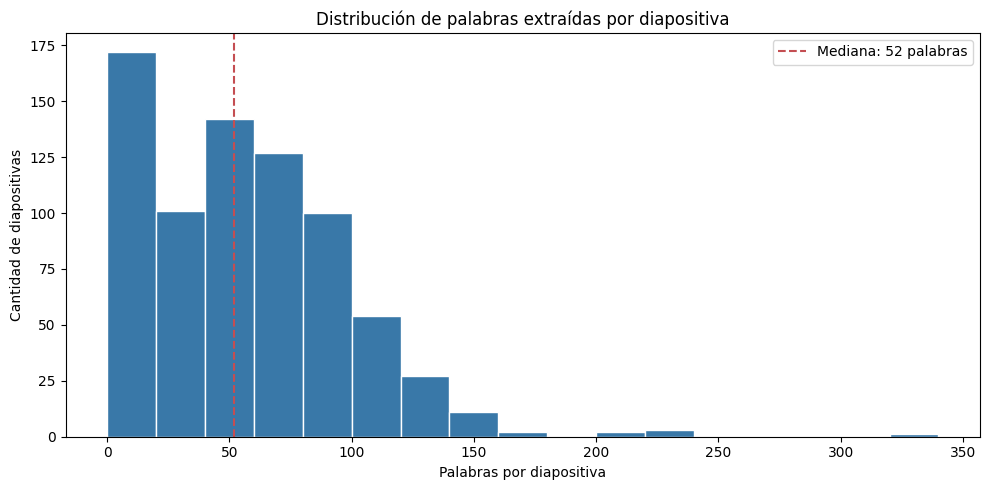

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))

maximo = int(paginas["palabras_calculadas"].max())
limites = list(range(0, maximo + 21, 20))

ax.hist(
    paginas["palabras_calculadas"],
    bins=limites,
    color="#3978A8",
    edgecolor="white",
)

mediana = paginas["palabras_calculadas"].median()

ax.axvline(
    mediana,
    color="#C44E52",
    linestyle="--",
    label=f"Mediana: {mediana:.0f} palabras",
)

ax.set_title("Distribución de palabras extraídas por diapositiva")
ax.set_xlabel("Palabras por diapositiva")
ax.set_ylabel("Cantidad de diapositivas")
ax.legend()

fig.tight_layout()
plt.show()

In [6]:
resumen_decisiones = (
    decisiones.groupby(["incluir", "motivo"])
    .size()
    .reset_index(name="paginas")
)

resumen_decisiones["porcentaje_del_total"] = (
    100 * resumen_decisiones["paginas"] / len(decisiones)
)

display(
    resumen_decisiones.style.format({
        "porcentaje_del_total": "{:.2f} %",
    })
)

,incluir,motivo,paginas,porcentaje_del_total
0,False,contenido_visual_no_recuperado,2,0.27 %
1,False,portada_identificada,11,1.48 %
2,False,separador_o_cierre_identificado,31,4.18 %
3,False,sin_contenido_de_estudio,1,0.13 %
4,True,texto_breve_conservado,127,17.12 %
5,True,texto_conservado,570,76.82 %


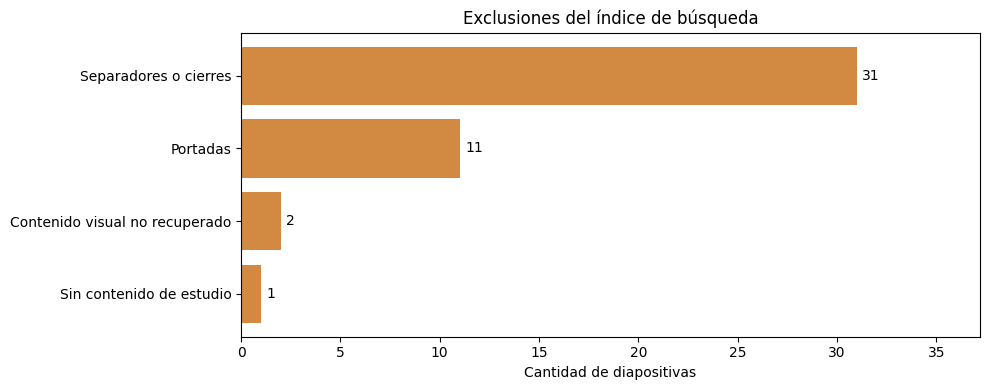

In [7]:
etiquetas = {
    "contenido_visual_no_recuperado": "Contenido visual no recuperado",
    "portada_identificada": "Portadas",
    "separador_o_cierre_identificado": "Separadores o cierres",
    "sin_contenido_de_estudio": "Sin contenido de estudio",
}

exclusiones = (
    decisiones.loc[~decisiones["incluir"], "motivo"]
    .value_counts()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(10, 4))

barras = ax.barh(
    [etiquetas.get(motivo, motivo) for motivo in exclusiones.index],
    exclusiones.values,
    color="#D28A43",
)

ax.bar_label(barras, padding=4)
ax.set_xlim(0, exclusiones.max() * 1.2)
ax.set_xlabel("Cantidad de diapositivas")
ax.set_title("Exclusiones del índice de búsqueda")

fig.tight_layout()
plt.show()

## Interpretación inicial

La mediana de 52 palabras por diapositiva respalda utilizar la página
como unidad base de recuperación, evitando cortes arbitrarios dentro
de explicaciones breves.

Las 172 páginas con menos de 20 palabras no se descartaron automáticamente.
La longitud por sí sola no permite distinguir una portada de una
definición breve o una diapositiva dependiente de imágenes.

La selección inicial conserva 697 páginas y excluye 45 mediante reglas
documentadas. Entre las incluidas, 127 páginas breves permanecen
señaladas para revisión visual.

Se identificaron dos páginas cuyo contenido visual no fue recuperado.
Esta limitación también puede presentarse en otras páginas con texto:
por ejemplo, la página del MAE conserva la explicación, pero no su fórmula.

Estos resultados describen la preparación del corpus. Todavía no
demuestran la calidad de recuperación ni de las respuestas del asistente.